# Lab 02: What is an agent

## Goal

Tell a chatbot, a workflow and an agent apart by one test: **who decides the next step?** We ask all three the same
question about a customer of the Chinook music shop and check every answer against the shop's database. The moment
that teaches it is the chatbot: it often answers correctly about one customer from its memory, and its right replies
read exactly like its wrong ones. Nothing was looked up in either case.

## What you will learn

- How to say who decides the next step in a chatbot, a workflow and an agent.
- How to answer a question with a workflow: fixed lookups on `chinook.db`, in an order our code sets.
- Why an answer from the model's memory is no evidence, even when it is right.
- How to write an agent by hand with a text protocol: one turn by hand, then a loop with a turn cap where the model
  picks the next lookup.
- How to check the agent's final answer in code against the database.
- How to count model calls and tokens for each shape and turn them into dollars.
- How to choose an autonomy level (suggest, draft, act with audit, act) for a job, and when an agent is the wrong
  choice.

**Coming from:** lab 01 sent a list of messages to the Chat Completions API and read the reply. That is all this lab
needs. Here the same call becomes a chatbot, and then one step of an agent. There is no tools API yet; lab 03 adds it.

## Chatbot, workflow and agent: who decides the next step

All three can answer a customer's question. They differ in who chooses what happens next:

- **Chatbot:** the model writes the reply from what it already knows. There is no next step to choose: one call,
  one reply.
- **Workflow:** our code runs steps we wrote in advance, in an order we chose. A model may be one of the steps, or
  there may be none at all.
- **Agent:** the model chooses the next step, our code runs it and sends back the result, and this repeats until
  the model says it is done or our code stops it.

In the picture below, the step that decides is filled: dark where the model decides, lime where our code does.

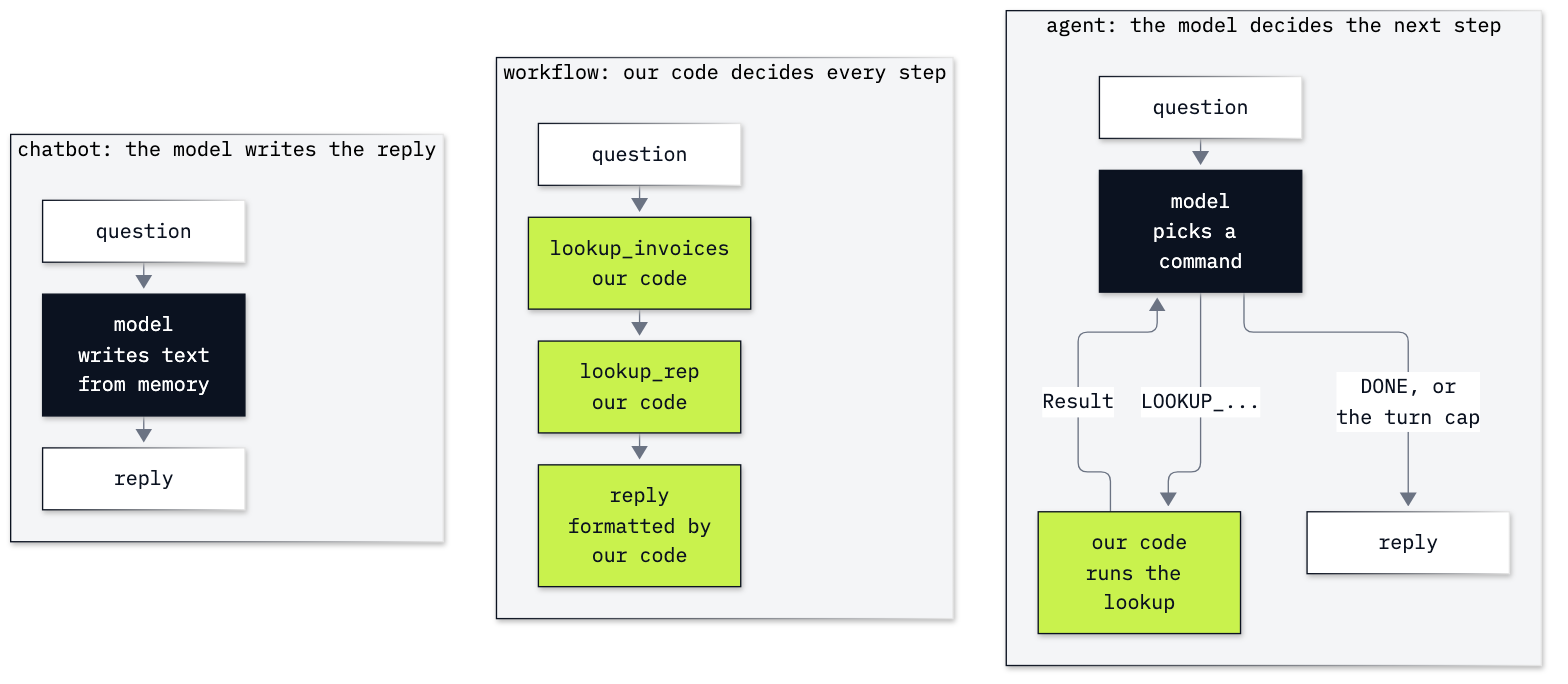

In [1]:
from IPython.display import Image

Image("resources/lab02_three_shapes.png", width=760)

The question for the whole lab is the shop's running question about its customer Helena Holý:

> How many invoices does Helena Holý have, how much has she spent, and who is her support rep?

Its answer has three facts, and all three live in the shop's database. We will ask the same question about a second
customer, Puja Srivastava.

## Setup

The config cell is the same in every lab (lab 00 explains it line by line). It finds the repository folder by
`models.env`, reads the model name and prices from it, and finds your key in `.env` without printing it. This lab
adds two imports: `sqlite3` for the database, and `OpenAI` with `omit` for the model calls (Part C says what `omit`
is for).

In [2]:
from pathlib import Path
import os
import sqlite3

from dotenv import dotenv_values
from openai import OpenAI, omit

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


## Part A: Look up the facts in the database

Before we ask any system, we need the right answer, so that we can check every reply against it. The shop's data is
in `data/chinook.db`, a SQLite file. We open it **read-only**: the address `file:...?mode=ro`, with `uri=True`, tells
SQLite to refuse every write, so nothing in this lab can change the shop's data. `check_same_thread=False` lets the
connection be used from another thread, which some later labs' frameworks do; every lab opens the database with the
same line.

In [3]:
# Open the shop's database read-only
db = sqlite3.connect(f"file:{ROOT / 'data' / 'chinook.db'}?mode=ro", uri=True, check_same_thread=False)

tables = db.execute("SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name")
print([row[0] for row in tables])

['albums', 'artists', 'customers', 'employees', 'genres', 'invoice_items', 'invoices', 'media_types', 'playlist_track', 'playlists', 'tracks']


Eleven tables. This question needs three: `customers`, `invoices` and `employees` (the support reps are employees).

**Helena's row.** We print the one record first, before we write anything that uses it. `fetchone()` returns the first
row of the result as a tuple.

In [4]:
row = db.execute(
    "SELECT CustomerId, FirstName, LastName, Country, SupportRepId FROM customers "
    "WHERE FirstName = 'Helena' AND LastName = 'Holý'"
).fetchone()
row

(6, 'Helena', 'Holý', 'Czech Republic', 5)

One tuple, one value per column we asked for:

| Position | Column | Value | What it is for |
|---|---|---|---|
| 0 | `CustomerId` | 6 | the key her invoices point to |
| 1, 2 | `FirstName`, `LastName` | Helena, Holý | how a person names her (note the ý) |
| 3 | `Country` | Czech Republic | where she lives |
| 4 | `SupportRepId` | 5 | her rep's `EmployeeId` in `employees`: a number here, not a name |

So two of our three facts are in other tables: the invoices point to customer 6, and the rep is employee 5.

In [5]:
invoices = db.execute(
    "SELECT InvoiceId, InvoiceDate, Total FROM invoices WHERE CustomerId = 6 ORDER BY InvoiceDate"
).fetchall()
for invoice in invoices:
    print(invoice)
print(len(invoices), "invoices, total", round(sum(total for _, _, total in invoices), 2))

(46, '2009-07-11 00:00:00', 8.91)
(175, '2011-02-15 00:00:00', 1.98)
(198, '2011-05-20 00:00:00', 3.96)
(220, '2011-08-22 00:00:00', 5.94)
(272, '2012-04-11 00:00:00', 0.99)
(393, '2013-10-03 00:00:00', 1.98)
(404, '2013-11-13 00:00:00', 25.86)
7 invoices, total 49.62


Seven rows, one per invoice, oldest first: the invoice number, the date and the amount. The amounts add up to 49.62.
The database stores amounts with no currency; this lab writes them in dollars. The last line unpacks each row as
`_, _, total` to keep only the third value (`_` is the usual name for a value we do not need).

In [6]:
db.execute("SELECT FirstName, LastName, Title FROM employees WHERE EmployeeId = 5").fetchone()

('Steve', 'Johnson', 'Sales Support Agent')

**The answer for Helena: 7 invoices, $49.62 in total, support rep Steve Johnson.**

We need the same three facts for any customer, by name, so we write each lookup once as a function. Each function
does in one query what the cells above did in steps:

- `JOIN` links each customer row to her invoice rows (or to her rep's row) through the ID columns we just read.
- `COUNT(i.InvoiceId)` counts her invoice rows, and `ROUND(SUM(i.Total), 2)` adds up their amounts, rounded to cents.
- `c.FirstName || ' ' || c.LastName` joins first and last name with a space between, so we can match a full name.
- `?` is a placeholder: SQLite puts the value from the tuple `(name,)` there. We never paste a name into the SQL
  text, so a name with a quote in it cannot break the query. The comma makes `(name,)` a tuple of one item.

In [7]:
def lookup_invoices(name):
    # How many invoices the customer with this full name has, and their total
    return db.execute(
        "SELECT COUNT(i.InvoiceId), ROUND(SUM(i.Total), 2) "
        "FROM customers c JOIN invoices i ON i.CustomerId = c.CustomerId "
        "WHERE c.FirstName || ' ' || c.LastName = ?",
        (name,),
    ).fetchone()


def lookup_rep(name):
    # The full name of the customer's support rep, or None when no customer has this name
    row = db.execute(
        "SELECT e.FirstName || ' ' || e.LastName "
        "FROM customers c JOIN employees e ON e.EmployeeId = c.SupportRepId "
        "WHERE c.FirstName || ' ' || c.LastName = ?",
        (name,),
    ).fetchone()
    return row[0] if row else None


print(lookup_invoices("Helena Holý"), lookup_rep("Helena Holý"))
print(lookup_invoices("Puja Srivastava"), lookup_rep("Puja Srivastava"))

(7, 49.62) Steve Johnson
(6, 36.64) Jane Peacock


Each function returns plain Python values: `lookup_invoices` a pair (count, total) and `lookup_rep` a string.
Helena's line matches the three cells above. Puja Srivastava, our second customer: 6 invoices, 36.64, Jane Peacock.

We keep both customers' facts in one dictionary, the **answer key**. Every reply in this lab is checked against it.

In [8]:
# The answer key: three facts per customer, read from the database
FACTS = {}
for name in ["Helena Holý", "Puja Srivastava"]:
    count, total = lookup_invoices(name)
    FACTS[name] = {"invoices": count, "total": total, "rep": lookup_rep(name)}

FACTS

{'Helena Holý': {'invoices': 7, 'total': 49.62, 'rep': 'Steve Johnson'},
 'Puja Srivastava': {'invoices': 6, 'total': 36.64, 'rep': 'Jane Peacock'}}

`FACTS` is keyed by the customer's full name; each value holds the three facts. **Only the question will go to the
model; the answer key never does.** It stays in our code, for checking.

**Checkpoint A**

| Customer | Invoices | Total | Support rep |
|---|---|---|---|
| Helena Holý | 7 | 49.62 | Steve Johnson |
| Puja Srivastava | 6 | 36.64 | Jane Peacock |

## Part B: Answer the question with a fixed workflow

We already know the steps this question needs: count and add up the invoices, then find the rep. When the steps are
known, code can run them in order. That is a workflow.

In [9]:
def workflow(name):
    # Two lookups in a fixed order, then a sentence. No model.
    count, total = lookup_invoices(name)
    rep = lookup_rep(name)
    return f"{name}: {count} invoices, ${total:.2f} in total, support rep {rep}."


print(workflow("Helena Holý"))
print(workflow("Puja Srivastava"))

Helena Holý: 7 invoices, $49.62 in total, support rep Steve Johnson.
Puja Srivastava: 6 invoices, $36.64 in total, support rep Jane Peacock.


Both answers are right, and no model was called. Who decided the next step? We did, when we wrote the function:
`lookup_invoices` first, `lookup_rep` second, then the sentence. Notice that the question never reaches this code.
`workflow` takes a name, not a question: we read the question ourselves when we wrote it.

That is also its limit. Ask *When was Helena's latest invoice?* and the workflow still has only these two steps;
someone has to write a new one. A workflow fits when the steps are known in advance and stay the same.

**Checkpoint B:** the same three facts as Part A for both customers, with 0 model calls.

## Part C: Ask a chatbot and check its answers against the database

A chatbot is a model call with no lookups: the question goes in, text comes out. Does the model know Helena's
numbers? It has never been sent a row of our database.

First the message list, printed before we send it: a system message that gives the model its role, and the user's
question. `QUESTION` holds the question with `{name}` where the customer goes, and `.format(name=...)` fills it in, so
both customers get the same text.

In [10]:
client = OpenAI()

QUESTION = "How many invoices does {name} have, how much has she spent, and who is her support rep?"
CHATBOT_SYSTEM = "You are the support assistant for Chinook, an online music shop."

chat_messages = [
    {"role": "system", "content": CHATBOT_SYSTEM},
    {"role": "user", "content": QUESTION.format(name="Helena Holý")},
]
chat_messages

[{'role': 'system',
  'content': 'You are the support assistant for Chinook, an online music shop.'},
 {'role': 'user',
  'content': 'How many invoices does Helena Holý have, how much has she spent, and who is her support rep?'}]

The call is the one from lab 01. `max_completion_tokens=200` caps the length of the reply. `reasoning_effort` comes
from `models.env` (`none` here, so the model spends no hidden reasoning tokens before it writes); when that setting is
empty, `EFFORT` is `None` and `EFFORT or omit` leaves the parameter out of the request, which a model without
reasoning (such as gpt-4o-mini) needs.

**Before you run it:** what will the model say about Helena? Write down a guess: the right numbers, invented numbers,
or a refusal.

In [11]:
chat_response = client.chat.completions.create(
    model=MODEL,
    messages=chat_messages,
    max_completion_tokens=200,
    reasoning_effort=EFFORT or omit,
)
print(chat_response.choices[0].message.content)

Helena Holý has **7 invoices**, totaling **$49.62**. Her support representative is **Martha Silva**.


In our run the model answered at once, in bold, with no doubt in its wording: 7 invoices and $49.62, both right, and the support rep **Martha Silva**. There is no Martha Silva in the database, as a customer or as an employee; Helena's rep is Steve Johnson. Nothing in the reply marks which parts the model remembered correctly and which it made up.

**A check that reads the reply.** To compare many replies we need the check in code. `facts_in` looks for each fact
the way the database writes it (`7 invoices`, `49.62`, `Steve Johnson`) and returns `True` or `False` for each.

In [12]:
def facts_in(reply, name):
    # Which of the customer's three facts the reply states, written as in the database
    facts = FACTS[name]
    return {
        "invoices": f"{facts['invoices']} invoices" in reply,
        "total": f"{facts['total']:.2f}" in reply,
        "rep": facts["rep"] in reply,
    }


facts_in(chat_response.choices[0].message.content, "Helena Holý")

{'invoices': True, 'total': True, 'rep': False}

`invoices` and `total` are `True` and `rep` is `False`: the check caught the invented rep.

What a pass means: the reply states the value in our database. What it cannot tell us: where the value came from. The
check reads only the text, and a number from memory looks the same as a number from a lookup. These are plain text
checks (`17 invoices` would also pass the first one), which is enough for replies this short.

**One reply is not enough.** The model can give a different reply each time it gets the same messages. We ask five
times for each customer and keep every reply. Only the question goes to the model each time.

In [13]:
chatbot_replies = {}
for name in FACTS:
    chatbot_replies[name] = []
    for run in range(5):
        response = client.chat.completions.create(
            model=MODEL,
            messages=[
                {"role": "system", "content": CHATBOT_SYSTEM},
                {"role": "user", "content": QUESTION.format(name=name)},
            ],
            max_completion_tokens=200,
            reasoning_effort=EFFORT or omit,
        )
        chatbot_replies[name].append(response.choices[0].message.content)

print({name: len(replies) for name, replies in chatbot_replies.items()})

{'Helena Holý': 5, 'Puja Srivastava': 5}


Ten replies, five per customer. Now each one beside the database's facts, with the result of `facts_in` in brackets.
`enumerate(replies, 1)` numbers the runs from 1, and `" ".join(reply.split())` puts a reply on one line.

In [14]:
for name, replies in chatbot_replies.items():
    facts = FACTS[name]
    print(f"{name}. Database: {facts['invoices']} invoices, {facts['total']}, rep {facts['rep']}")
    for run, reply in enumerate(replies, 1):
        found = facts_in(reply, name)
        marks = ", ".join(f"{fact} {'yes' if ok else 'no'}" for fact, ok in found.items())
        print(f"  run {run} [{marks}] {' '.join(reply.split())}")
    print()

Helena Holý. Database: 7 invoices, 49.62, rep Steve Johnson
  run 1 [invoices yes, total yes, rep yes] Helena Holý has **7 invoices** totaling **€49.62**. Her support representative is **Steve Johnson**.
  run 2 [invoices yes, total yes, rep no] Helena Holý has **7 invoices**, totaling **$49.62**. Her support representative is **Jane Peacock**.
  run 3 [invoices yes, total yes, rep yes] Helena Holý has **7 invoices**, totaling **$49.62**. Her support representative is **Steve Johnson**.
  run 4 [invoices yes, total yes, rep yes] Helena Holý has **7 invoices** totaling **$49.62**. Her support representative is **Steve Johnson**.
  run 5 [invoices yes, total yes, rep yes] Helena Holý has **7 invoices** totaling **€49.62**. Her support representative is **Steve Johnson**.

Puja Srivastava. Database: 6 invoices, 36.64, rep Jane Peacock
  run 1 [invoices no, total no, rep no] I don’t have access to Chinook’s customer or invoice records here, so I can’t verify Puja Srivastava’s invoice count

Read the replies before the count. Then the count: in how many runs did a reply hold all three facts?

In [15]:
for name, replies in chatbot_replies.items():
    right = sum(all(facts_in(reply, name).values()) for reply in replies)
    print(f"{name}: all three facts right in {right} of {len(replies)} runs; facts looked up: 0")

Helena Holý: all three facts right in 4 of 5 runs; facts looked up: 0
Puja Srivastava: all three facts right in 0 of 5 runs; facts looked up: 0


In our run, for **Helena**, all three facts were right in 4 of 5 replies. Run 2 named Jane Peacock as her rep: a real rep at the shop, but Puja's, not Helena's. Runs 1 and 5 wrote the total as €49.62; the database stores no currency, so the euro sign is the model's own addition. Right or wrong, every reply has the same shape and the same bold numbers. For **Puja** the model refused in all 5 runs: it said it has no access to the shop's records. The last column, `facts looked up: 0`, is true in every run by construction: this call has no way to look anything up.

**Key lesson: a right answer from memory looks exactly like a wrong one, and nothing was looked up in either.**
Chinook is a public sample database, copied into many tutorials, so the model has most likely seen Helena's numbers
in its training data. Puja is in the same public database, yet the model refused for her in all five runs. What a model remembers is uneven, and the
reply does not tell you which case you are in. The customers of a real shop were never in its training data at all.

⚠️ **Important:** never treat a correct answer from a model with no lookups as a lookup. A number that matters comes
from the system that holds it.

**Checkpoint C:** every reply printed beside the facts. For Helena, the count and total right in most runs and the rep not always (ours: all three facts in 4 of 5 runs, Jane Peacock in run 2, and Martha Silva, a name not in the database, in the first call above). For Puja, a refusal or a wrong answer, never a lookup (ours: refused in 5 of 5).

The workflow looked the facts up but cannot read a question. The chatbot reads the question but cannot look anything
up. An agent does both: the model reads the question and picks the lookups, and our code runs them.

## Part D: Let the model choose the next lookup

An agent needs a way for the model to ask for a lookup. The model can only send text, so we agree on a format first:
a **text protocol**. Each reply is one line holding one command:

| Command | What our code does |
|---|---|
| `LOOKUP_INVOICES <customer full name>` | runs `lookup_invoices` and sends back the count and the total |
| `LOOKUP_REP <customer full name>` | runs `lookup_rep` and sends back the rep's name |
| `DONE <answer>` | nothing: the answer is final and the loop stops |

Lab 03 replaces this home-made format with the API's own tool calls. The idea stays the same: the model asks, and our
code runs.

### Step 1: Split one command line

A command line holds a command and a name, separated by the first space. `str.partition(" ")` splits a string at the
first space and returns three parts: what comes before it, the space itself, and the rest.

In [16]:
"LOOKUP_REP Helena Holý".partition(" ")

('LOOKUP_REP', ' ', 'Helena Holý')

The command, the separator (which we throw away), and the name with its own space kept inside. `split()` would have
cut *Helena Holý* in two.

### Step 2: Run one command

`run_command` takes one line, runs the lookup it names and returns the result as **text**, because text is what we
will send back to the model. A name with no customer, or a command it does not know, comes back as a short message
instead of an error, so the model can read it and try again.

In [17]:
def run_command(line):
    # Run one LOOKUP_ line and return the result as text for the model
    command, _, name = line.partition(" ")
    if command == "LOOKUP_INVOICES":
        count, total = lookup_invoices(name)
        return f"{count} invoices, total {total}" if count else f"no customer named {name}"
    if command == "LOOKUP_REP":
        return lookup_rep(name) or f"no customer named {name}"
    return "unknown command: reply with LOOKUP_INVOICES, LOOKUP_REP or DONE"


print(run_command("LOOKUP_INVOICES Helena Holý"))
print(run_command("LOOKUP_REP Puja Srivastava"))
print(run_command("REFUND Helena Holý"))

7 invoices, total 49.62
Jane Peacock
unknown command: reply with LOOKUP_INVOICES, LOOKUP_REP or DONE


Two results from the database, and a message for a command the protocol does not have.

### Step 3: Run the loop on a plan we wrote

Before the model chooses anything, here is the loop an agent runs, with each next step taken from a list we wrote.

In [18]:
plan = ["LOOKUP_INVOICES Helena Holý", "LOOKUP_REP Helena Holý", "DONE"]

for line in plan:
    if line.startswith("DONE"):
        print("DONE: stop")
        break
    print(line, "->", run_command(line))

LOOKUP_INVOICES Helena Holý -> 7 invoices, total 49.62
LOOKUP_REP Helena Holý -> Steve Johnson
DONE: stop


The loop ran two lookups and stopped at `DONE`. This is still a workflow, because we wrote the plan. An agent keeps the
loop and deletes the list: the model writes each next line, after reading the results so far.

### Step 4: Tell the model the protocol

The system prompt is the protocol in words. Each line has a job: who the model is and that it cannot see the data;
the one-line format; the three commands, with what each returns; and the rule to look facts up instead of answering
from memory.

In [19]:
AGENT_SYSTEM = """You are the support assistant for Chinook, an online music shop. You cannot see the shop's database yourself.
Reply with exactly one line, and make it one of these commands:
LOOKUP_INVOICES <customer full name>  (returns how many invoices the customer has and their total)
LOOKUP_REP <customer full name>  (returns the customer's support rep)
DONE <your answer to the user>
Look up every fact before you answer. Never answer from memory."""

print(AGENT_SYSTEM)

You are the support assistant for Chinook, an online music shop. You cannot see the shop's database yourself.
Reply with exactly one line, and make it one of these commands:
LOOKUP_INVOICES <customer full name>  (returns how many invoices the customer has and their total)
LOOKUP_REP <customer full name>  (returns the customer's support rep)
DONE <your answer to the user>
Look up every fact before you answer. Never answer from memory.


### Step 5: Run turn 1 by hand

The message list starts like the chatbot's: the system prompt and the question. We call the model once and look at
what comes back. **Before you run it:** will the reply be an answer, or a command?

In [20]:
messages = [
    {"role": "system", "content": AGENT_SYSTEM},
    {"role": "user", "content": QUESTION.format(name="Helena Holý")},
]
response = client.chat.completions.create(
    model=MODEL, messages=messages, max_completion_tokens=100, reasoning_effort=EFFORT or omit
)
line = response.choices[0].message.content.strip()
print(line)

LOOKUP_INVOICES Helena Holý


The model did not answer. It wrote `LOOKUP_INVOICES Helena Holý`: a request for a lookup, in our format, with her full name as the argument. Nothing has run yet: the line is only text until our code acts on it.

In [21]:
result = run_command(line)
print(result)

7 invoices, total 49.62


Our code ran the lookup. Now both go into the message list: the model's line as an `assistant` message, and the result
as a `user` message that starts with `Result:`.

**Why does the result go back as a `user` message?** Chat Completions has the roles `system`, `user`, `assistant` and
`tool`. A `tool` message must answer a tool call that the API itself recorded, and our text protocol makes no such
calls: to the API, a `LOOKUP_` line is ordinary assistant text. So the result goes back as a user turn, and the
`Result:` label lets the model tell it apart from the person's question. Lab 03 introduces tool calls and the `tool`
role.

In [22]:
messages.append({"role": "assistant", "content": line})
messages.append({"role": "user", "content": "Result: " + result})

for message in messages:
    print(f"{message['role']:9} {message['content'].splitlines()[0]}")

system    You are the support assistant for Chinook, an online music shop. You cannot see the shop's database yourself.
user      How many invoices does Helena Holý have, how much has she spent, and who is her support rep?
assistant LOOKUP_INVOICES Helena Holý
user      Result: 7 invoices, total 49.62


Four messages: the system prompt (its first line shown), the question, the model's command and our result. **This
list is the agent's memory.** The model keeps nothing between calls, so all it knows about this conversation is the
list we send.

### Step 6: Run turn 2 by hand

The same call with the longer list. The model now sees the invoice result and picks again.

In [23]:
response = client.chat.completions.create(
    model=MODEL, messages=messages, max_completion_tokens=100, reasoning_effort=EFFORT or omit
)
line = response.choices[0].message.content.strip()
result = run_command(line)
print(line, "->", result)

messages.append({"role": "assistant", "content": line})
messages.append({"role": "user", "content": "Result: " + result})

LOOKUP_REP Helena Holý -> Steve Johnson


With the invoice result in front of it, the model asked for the fact still missing, `LOOKUP_REP Helena Holý`, and our code returned Steve Johnson. All three facts are now in the list, and all came from the database; the model chose the order. One more call would bring the `DONE` line, and the loop below makes that call for us.

### Step 7: Package the turns in a loop with a turn cap

You have seen two turns. The loop repeats the same three steps:

1. Send the message list to the model.
2. If the reply starts with `DONE`, stop: that line is the answer.
3. Otherwise run the command, append the model's line and the result, and go back to step 1.

We add one rule of our own, a **turn cap**. If the model never writes `DONE` (it keeps asking, or writes something
that is not a command), the loop would call the model, and bill us, without end. `max_turns=5` stops it after five
calls. When the cap stops the loop, the last message is a result instead of a `DONE` line, so our code can tell it
never finished. `run_agent` also keeps each call's `usage` (its token counts) for Part E.

In [24]:
def run_agent(question, max_turns=5):
    # Let the model pick lookups until it replies DONE or the turn cap is reached
    messages = [
        {"role": "system", "content": AGENT_SYSTEM},
        {"role": "user", "content": question},
    ]
    usages = []
    for turn in range(max_turns):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, max_completion_tokens=100, reasoning_effort=EFFORT or omit
        )
        usages.append(response.usage)
        line = response.choices[0].message.content.strip()
        messages.append({"role": "assistant", "content": line})
        if line.startswith("DONE"):
            break
        messages.append({"role": "user", "content": "Result: " + run_command(line)})
    return messages, usages

We run it on Helena from a fresh list and print every message after the system prompt.

In [25]:
agent_messages, agent_usages = run_agent(QUESTION.format(name="Helena Holý"))

for message in agent_messages[1:]:
    print(f"{message['role']:9} {message['content']}")
print("model calls:", len(agent_usages))

user      How many invoices does Helena Holý have, how much has she spent, and who is her support rep?
assistant LOOKUP_INVOICES Helena Holý
user      Result: 7 invoices, total 49.62
assistant LOOKUP_REP Helena Holý
user      Result: Steve Johnson
assistant DONE Helena Holý has 7 invoices totaling $49.62, and her support rep is Steve Johnson.
model calls: 3


Three model calls: `LOOKUP_INVOICES`, `LOOKUP_REP`, then `DONE` with the answer (7 invoices, $49.62, Steve Johnson). It is the same order as our workflow, but this time the model chose it after reading the question. Each fact in the `DONE` line is also in a `Result:` line above it, sent by our code from the database.

### Step 8: Check the answer in code

The loop stopped because the model wrote `DONE`. That tells us the model thinks it has finished. Whether the answer
holds all three facts is a separate question: a model could stop after one lookup and answer with two facts, and the
loop would stop just the same. **A stop condition says when the loop ends; only a check says whether the answer is
right.** So our code checks the `DONE` line with the same `facts_in` as the chatbot's replies.

In [26]:
done_line = agent_messages[-1]["content"]
print(done_line)
facts_in(done_line, "Helena Holý")

DONE Helena Holý has 7 invoices totaling $49.62, and her support rep is Steve Johnson.


{'invoices': True, 'total': True, 'rep': True}

All three are `True`: the `DONE` line holds the database's facts. A pass shows the answer is right in this run. It says nothing about the next run, so we run the agent again.

### Step 9: Run the agent five times for each customer

The model chooses again on every run, so one good run proves little. We run the agent five times for each customer
and print the commands it picked, then the check on its last line. `m["content"].split()[0]` keeps the first word of
each line the model wrote: its command. `passed += ok` adds 1 for each run that passed, since `True` counts as 1.

In [27]:
passed = 0
for name in FACTS:
    for run in range(5):
        messages, usages = run_agent(QUESTION.format(name=name))
        steps = [m["content"].split()[0] for m in messages if m["role"] == "assistant"]
        final = messages[-1]["content"]
        ok = final.startswith("DONE") and all(facts_in(final, name).values())
        passed += ok
        print(f"{name:16} run {run + 1}: {' -> '.join(steps):40} all three facts: {'yes' if ok else 'no'}")

print(f"\n{'✅' if passed == 10 else '❌'} all three facts in {passed} of 10 runs")

Helena Holý      run 1: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Helena Holý      run 2: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Helena Holý      run 3: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Helena Holý      run 4: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Helena Holý      run 5: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Puja Srivastava  run 1: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Puja Srivastava  run 2: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Puja Srivastava  run 3: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Puja Srivastava  run 4: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes


Puja Srivastava  run 5: LOOKUP_INVOICES -> LOOKUP_REP -> DONE    all three facts: yes

✅ all three facts in 10 of 10 runs


The same three commands in the same order in all 10 runs, and all three facts in every `DONE` line, for Puja as well as Helena. The model took the same path each time, but nothing in our code fixed that path: another question can get another path, and the challenge shows one.

Helena's chatbot replies passed `facts_in` too, in some runs. So what makes the agent's answer different? Its message
list. `results_sent` collects the lookup results our code sent back to the model in a list of messages.

In [28]:
def results_sent(messages):
    # The lookup results our code sent back to the model in this message list
    return [m["content"] for m in messages if m["role"] == "user" and m["content"].startswith("Result:")]


print("chatbot:", results_sent(chat_messages))
print("agent:  ", results_sent(agent_messages))

chatbot: []
agent:   ['Result: 7 invoices, total 49.62', 'Result: Steve Johnson']


The chatbot's list holds the question and nothing else; the agent's holds the two results from our database.
**The check tells you whether the answer is right; the message list tells you where it came from.** For Helena both
can look right. For Puja, the chatbot refused in all five runs, while the agent's `DONE` line held 6 invoices, 36.64 and Jane Peacock in all five, because it could look them up.

**Checkpoint D:** the agent's commands `LOOKUP_INVOICES -> LOOKUP_REP -> DONE`, and all three facts in the `DONE`
line, in 10 of 10 runs; two `Result:` messages in the agent's list and none in the chatbot's.

## Part E: Count the model calls and tokens of each shape

Each shape has a price. We count it on one Helena question: model calls, input tokens (what we send), output tokens
(what the model writes), and dollars from the prices in `models.env`. The workflow made no calls. The chatbot made one
in Part C (`chat_response`). The agent's calls are in `agent_usages` from Step 7.

First the agent's calls one by one, as (input tokens, output tokens):

In [29]:
[(usage.prompt_tokens, usage.completion_tokens) for usage in agent_usages]

[(130, 17), (159, 10), (180, 25)]

Three calls: 130, 159 and 180 input tokens, and 17, 10 and 25 output tokens. Input grows on every call because we resend the whole list: the system prompt, the question and
every command and result so far.

Now all three shapes side by side. `price` turns token counts into dollars with the per-million prices from
`models.env`.

In [30]:
price_in = float(settings["PRICE_INPUT_PER_MILLION"])
price_out = float(settings["PRICE_OUTPUT_PER_MILLION"])


def price(input_tokens, output_tokens):
    return input_tokens * price_in / 1_000_000 + output_tokens * price_out / 1_000_000


shapes = {"workflow": [], "chatbot": [chat_response.usage], "agent": agent_usages}

print(f"{'shape':9} {'calls':>5} {'input':>6} {'output':>6} {'per question':>13} {'per 100,000':>12}")
for shape, usages in shapes.items():
    tokens_in = sum(usage.prompt_tokens for usage in usages)
    tokens_out = sum(usage.completion_tokens for usage in usages)
    cost = price(tokens_in, tokens_out)
    print(f"{shape:9} {len(usages):>5} {tokens_in:>6} {tokens_out:>6} {cost:>13.6f} {cost * 100_000:>12.2f}")

shape     calls  input output  per question  per 100,000
workflow      0      0      0      0.000000         0.00
chatbot       1     46     30      0.000020         1.96
agent         3    469     52      0.000073         7.29


The cost of one call, with the prices from `models.env`:

$$\text{cost} = \text{input tokens} \times \frac{\$0.10}{1{,}000{,}000} + \text{output tokens} \times \frac{\$0.50}{1{,}000{,}000}$$

For the agent's three calls together: $469 \times 0.10 / 1{,}000{,}000 + 52 \times 0.50 / 1{,}000{,}000 = \$0.0000469 + \$0.0000260 = \$0.0000729$, which the table rounds to 0.000073.

Read the table row by row. The workflow costs nothing and was right in every run. The chatbot costs $0.000020 a question ($1.96 per 100,000 questions) and held all three facts in 4 of 5 Helena runs and in none of Puja's. The agent costs $0.000073 ($7.29 per 100,000), about 3.7 times the chatbot, and was right in 10 of 10. Most of its cost is input: 469 of its 521 tokens, because the system prompt and the growing list are sent three times. One question costs a fraction of a cent in every shape; the difference that matters is per question, repeated at volume: an agent that spends three calls where a workflow needs none pays that difference on every question.

These prompts are far below the 1,024 tokens where prompt caching starts, so all input is billed at the full input
price.

**So when is the agent worth its calls?** When we cannot write the steps in advance. The workflow has no step for a
question nobody foresaw; the agent can combine its commands in an order nobody wrote. The challenge shows what happens
when the command it needs is missing.

**Checkpoint E:** 0 / 1 / 3 model calls for workflow, chatbot and agent; in our run 46 input and 30 output tokens for the chatbot, 469 and 52 for the agent, so $0.000020 and $0.000073 a question. Token counts move a little from run to run.

## Part F: Choose an autonomy level, or no agent at all

Shape is who decides the next step. **Autonomy** is a separate choice: how far the agent may act before a person
sees what it did. Our question only read data. A request that changes something needs this choice, and the shop's
running request is a refund email: *I was charged twice last month, please fix it.* Ticket 14 in the shop's support
files is that case, and the refunds policy has a rule for it:

In [31]:
corpus = ROOT / "data" / "corpus"
print((corpus / "ticket_14_duplicate_invoice.md").read_text())

for line in (corpus / "policy_refunds.md").read_text().splitlines():
    if line.startswith("Duplicate charges"):
        print(line)

# Ticket 14 — Duplicate digital charge

Date: 2013-11-02
Customer: email on file, digital album The Essential Miles Davis

Two invoices, same album, same day, 9.99 each. Refunds policy: refund the later invoice in full.

Status: open. Assigned representative still reviewing both invoice numbers.

Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.


Two invoices for the same album on the same day, 9.99 each, and a rule: refund the later invoice in full. An agent
could find both invoices and file the refund. The question is what it may do without a person.

Picture the email arriving at 3 a.m. on a Saturday, and the agent picking the wrong invoice. What has already happened
by Monday morning?

| Level | The agent | A person | By Monday, if it picked the wrong invoice |
|---|---|---|---|
| `suggest` | says which invoice looks like the duplicate, and why | checks, then files the refund | nothing: the rep sees the mistake before acting |
| `draft` | prepares the refund (the invoice, 9.99, both invoice numbers attached) and waits | approves, edits or rejects it | nothing has been paid; the wrong draft waits in the queue |
| `act with audit` | files the refund and logs what it did, in a way that can be undone | reviews the log | a wrong refund went out; the log shows which, so it can be reversed |
| `act` | files the refund, with no one in the loop | nobody | a wrong refund went out, and nobody knows yet |

A chatbot sits at `suggest`, since it can only talk. An agent that can move money should not sit at `act`.

**Three cases where you should not use an agent:**

1. **The steps are known in advance.** A workflow is cheaper, takes the same path every run, and is easy to test and
   to explain (Parts B and E).
2. **A wrong action is expensive or hard to undo.** Keep the agent at `suggest` or `draft`, or write a rules workflow
   that a person can read ("refund the later of two same-day invoices for the same album").
3. **The facts were never written down.** A lookup can only fetch what a system stores. With no record to look up, an
   agent is left with the model's memory, and Part C showed what that is worth.

**Your turn: six jobs.** For each job, decide the shape (chatbot, workflow or agent), who decides the next step, and
the autonomy level. Some rows have more than one answer you could defend; write the one you would defend to a risk
team. Our answers, with the reasons, are in `solved/02_what_is_an_agent_solution.ipynb`.

| # | Job | Shape | Who decides the next step? | Autonomy |
|---|---|---|---|---|
| 1 | Send the same overdue reminder to every account more than 30 days late | | | |
| 2 | A visitor asks what jazz fusion is | | | |
| 3 | A messy email with an invoice question, an address change and a complaint | | | |
| 4 | Refund duplicate charges straight from the inbox, up to a set limit, with no one in the loop | | | |
| 5 | Route each incoming request to billing, shipping or product | | | |
| 6 | Find out why revenue fell last quarter | | | |

**Checkpoint F:** your table filled in, and compared with the solution's. Rows 4 and 5 are the ones where people
disagree.

## What you can do now

- Say who decides the next step in a chatbot (the model writes the reply), a workflow (our code) and an agent (the
  model picks, our code runs).
- Write a workflow: lookups on `chinook.db` in a fixed order, right in every run, with no model call.
- Explain why a right answer from memory is no evidence, with this lab's Helena and Puja replies as the example.
- Write an agent with a text protocol: the system prompt, one turn by hand (call, parse, run, append), then a loop
  with a turn cap.
- Check the final answer in code against the database, and read the message list for where it came from.
- Count calls and tokens for each shape and price them from `models.env`.
- Choose an autonomy level for a job, and name the three cases where an agent is the wrong choice.

## Challenge: add a command for a question the protocol cannot answer

Ask the agent: *When was Helena Holý's latest invoice, and how much was it?*

1. **Run the agent as it is** with `run_agent` and print the message list. No command returns a date, so expect the
   model to look up what it can (`LOOKUP_INVOICES`) and then say in its `DONE` line that the date is not in the
   result, or answer with the count and total instead. Either way it should not invent a date.
2. **Add a command.** Write `lookup_latest_invoice(name)`, which returns the date and total of the customer's newest
   invoice (`ORDER BY i.InvoiceDate DESC LIMIT 1`). Add a line for `LOOKUP_LATEST_INVOICE <customer full name>` to
   `AGENT_SYSTEM` and a branch for it to `run_command`. `run_agent` reads both names each time it runs, so redefining
   them is enough. Expect the commands `LOOKUP_LATEST_INVOICE -> DONE` (two model calls) and an answer with
   2013-11-13 and 25.86; check those two values with your own query first.
3. **Check it in code.** Run the new agent five times and check each `DONE` line for the date and the total.

Notice what you changed in task 2: you gave the model one more option, not a new step. Nothing tells it when to use
the new command; it decides from the question. A worked solution, run, is in
`solved/02_what_is_an_agent_solution.ipynb`.

## Resources

- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages`, `max_completion_tokens`, `reasoning_effort` and `usage`
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state): why the list of
  messages is the model's only memory
- [OpenAI: A practical guide to building agents](https://cdn.openai.com/business-guides-and-resources/a-practical-guide-to-building-agents.pdf):
  when an agent fits, and where people stay in the loop
- [Anthropic: Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): workflows
  (steps set in code) and agents (the model directs its own steps), and when each fits
- [Python: `sqlite3`](https://docs.python.org/3/library/sqlite3.html) and [SQLite: URI filenames](https://www.sqlite.org/uri.html):
  placeholders, and opening a database with `mode=ro`